# Nutri-Score unter der Lupe – Projektarbeit Teil 1

**Modul:** Data Engineering HS26, ZHAW School of Management and Law
**Gruppe:** Cindy Sommer, Andrea Brunetto
**Abgabe:** 27.10.2026 · **Datenstand (Snapshot):** 06.10.2026

## Ziel
Wir prüfen, ob ein gutes Nutri-Score-Label (A/B) auch bedeutet, dass ein Lebensmittel wenig verarbeitet ist.
Dazu bauen wir eine Datenpipeline nach dem Data-Engineering-Lebenszyklus (Reis & Housley, 2022)
und testen vier vorab festgelegte Hypothesen (H1–H4).

## Aufbau des Notebooks

| Abschnitt | Lebenszyklus-Phase | Ergebnis |
|---|---|---|
| 1 | Setup | Pfade, Snapshot-Datum, Datenbankverbindung |
| 2 | Ingestion | Parquet-Export von Open Food Facts lokal gespeichert |
| 3 | Storage: Bronze | Schweizer Produkte, relevante Spalten, Werte unverändert |
| 4 | Transformation: Silver | Bereinigte Tabelle + Protokoll der entfernten Zeilen |
| 5 | Initiale Analyse (EDA) | Vollständigkeit, Kreuztabelle, Grafik |
| 6 | Storage: Gold | Eine Auswertungstabelle pro Hypothese |
| 7 | Hypothesentests H1–H4 | Kennzahlen, p-Werte, Entscheid |
| 8 | Zusammenfassung + Stichprobe | Werte für die Präsentation, CSV-Sample für GitHub |

## Ausführen
Zellen von oben nach unten ausführen (*Run → Run All Cells*). Beim ersten Lauf wird der Rohdatenexport
(mehrere GB) heruntergeladen; danach wird der Download übersprungen.

## Datenquelle und Lizenz
Open Food Facts, Open Database License (ODbL 1.0).
*Contains data from Open Food Facts, available under the Open Database License.*

## Zitierweise im Code
Externe Quellen (Literatur, Dokumentation, Code-Vorlagen) sind gemäss ZHAW-Zitierleitfaden direkt im Code
mit `# Quelle: …` gekennzeichnet. Das vollständige Verzeichnis steht am Ende des Notebooks.

## 1 · Setup

Hier werden alle Einstellungen an einer Stelle festgelegt.
`SNAPSHOT_DATE` hält fest, welcher Datenstand ausgewertet wird (Unterströmung *Data Management*:
Reproduzierbarkeit). Open Food Facts ändert sich täglich; ohne festes Datum wären die Resultate nicht nachvollziehbar.

In [1]:
# --- Bibliotheken ------------------------------------------------------------
from pathlib import Path   # plattformunabhängige Dateipfade (Windows und Mac)
import os                  # Umgebungsvariablen lesen (optional, für Tests)

import duckdb              # eingebettete, spaltenorientierte SQL-Datenbank (Storage)
import pandas as pd        # Tabellen in Python (Anzeige, Pivot)
from scipy import stats    # statistische Tests (Binomial, Chi-Quadrat, Spearman)

# --- Konfiguration -----------------------------------------------------------
# Fester Datenstand: NICHT ändern, sonst werden andere Rohdaten ausgewertet.
SNAPSHOT_DATE = os.environ.get("SNAPSHOT_DATE", "2026-10-06")

# Länder-Tag, mit dem Open Food Facts Schweizer Produkte kennzeichnet
COUNTRY_TAG = "en:switzerland"

# Signifikanzniveau für alle Hypothesentests (vorab festgelegt)
ALPHA = 0.05

# --- Ordnerstruktur (Medallion-Architektur) ----------------------------------
# raw/    : unveränderter Gesamtexport (mehrere GB, NICHT auf GitHub)
# bronze/ : Schweizer Auszug, Werte unverändert (auf GitHub)
# sample/ : kleine CSV-Stichprobe zum schnellen Ansehen (auf GitHub)
# Silver und Gold liegen als Tabellen in der DuckDB-Datei.
DATA_DIR = Path(os.environ.get("DATA_DIR", "data"))
RAW_DIR = DATA_DIR / "raw"
BRONZE_DIR = DATA_DIR / "bronze"
SAMPLE_DIR = DATA_DIR / "sample"
DB_PATH = DATA_DIR / "nutriscore.duckdb"
for d in (RAW_DIR, BRONZE_DIR, SAMPLE_DIR):
    d.mkdir(parents=True, exist_ok=True)   # Ordner anlegen, falls noch nicht vorhanden

# Dateinamen enthalten das Snapshot-Datum -> jeder Datenstand bleibt eindeutig zuordenbar
RAW_FILE = RAW_DIR / f"off_food_{SNAPSHOT_DATE}.parquet"
BRONZE_FILE = BRONZE_DIR / f"off_ch_{SNAPSHOT_DATE}.parquet"

# Quelle: Open Food Facts (2026). Data, API and SDKs. https://world.openfoodfacts.org/data
# (Parquet-Export, gehostet auf Hugging Face)
PARQUET_URL = "https://huggingface.co/datasets/openfoodfacts/product-database/resolve/main/food.parquet?download=true"

# Verbindung zur lokalen DuckDB-Datei (wird beim ersten Mal automatisch erstellt)
con = duckdb.connect(str(DB_PATH))
print("Snapshot:", SNAPSHOT_DATE, "| Datenbank:", DB_PATH)

Snapshot: 2026-10-06 | Datenbank: data\nutriscore.duckdb


## 2 · Ingestion: Export herunterladen

**Entscheid Batch statt Streaming:** Open Food Facts erstellt den Export einmal pro Nacht, und unsere Analyse ist
nicht zeitkritisch.
**Entscheid Bulk-Export statt API:** Die API ist für Einzelabfragen gedacht; das Abfragen der ganzen Datenbank
über die API wird blockiert. Für Massendaten stellt Open Food Facts die Exporte bereit (Open Food Facts, 2026).

In [2]:
import requests   # HTTP-Download

def download(url: str, target: Path, chunk_mb: int = 8) -> Path:
    '''Lädt eine grosse Datei blockweise herunter.

    - Existiert die Zieldatei schon, wird nichts heruntergeladen (idempotent).
    - Es wird zuerst in eine .part-Datei geschrieben und erst am Ende umbenannt.
      So gilt ein abgebrochener Download nie als fertige Datei.
    - Blockweises Schreiben hält den Arbeitsspeicherbedarf klein (Skalierbarkeit).
    '''
    if target.exists():
        print(f"Bereits vorhanden: {target} ({target.stat().st_size / 1e9:.2f} GB)")
        return target
    tmp = target.with_suffix(".part")
    # Eigener User-Agent: von Open Food Facts für automatisierte Zugriffe verlangt
    headers = {"User-Agent": "ZHAW-DataEngineering-Projekt/1.0 (Studienprojekt)"}
    with requests.get(url, stream=True, timeout=60, headers=headers) as r:
        r.raise_for_status()                                   # bei HTTP-Fehler abbrechen
        total = int(r.headers.get("content-length", 0))        # Gesamtgrösse für Fortschritt
        done = 0
        with open(tmp, "wb") as f:
            for chunk in r.iter_content(chunk_size=chunk_mb * 1024 * 1024):
                f.write(chunk)
                done += len(chunk)
                if total:
                    print(f"\r{done / 1e9:.2f} / {total / 1e9:.2f} GB", end="")
    tmp.rename(target)                                         # erst jetzt gilt die Datei als fertig
    print(f"\nGespeichert: {target}")
    return target

download(PARQUET_URL, RAW_FILE)

Bereits vorhanden: data\raw\off_food_2026-10-06.parquet (7.91 GB)


WindowsPath('data/raw/off_food_2026-10-06.parquet')

### Schema prüfen

Bevor wir weiterarbeiten, kontrollieren wir, ob alle benötigten Spalten vorhanden sind.
Einige Felder sind verschachtelt:
- `nutriments`: Liste von Einträgen mit `name` (z. B. `sugars`) und dem Wert pro 100 g im Feld `"100g"`
- `product_name`: Liste von Einträgen mit `lang` (Sprache) und `text`
- `countries_tags`, `categories_tags`: Listen von Tags wie `en:switzerland`

Ergebnis am 06.10.2026: alle Spalten vorhanden. Es gibt **kein Feld zur Version des Nutri-Score-Algorithmus**
(alt oder 2024) – das ist relevant für Forschungsfrage FF3 in Teil 2.

In [3]:
# DESCRIBE liest nur die Metadaten der Parquet-Datei, nicht die Daten selbst -> sehr schnell
schema = con.sql(f"DESCRIBE SELECT * FROM read_parquet('{RAW_FILE}')").df()

needed = ["code", "product_name", "countries_tags", "categories_tags", "nutriscore_grade",
          "nutriscore_score", "nova_group", "additives_n", "nutriments"]
missing = [c for c in needed if c not in set(schema["column_name"])]
print("Fehlende Spalten:", missing or "keine")
print(schema[schema["column_name"].isin(needed)][["column_name", "column_type"]].to_string(index=False))

# Für FF3 (Teil 2): Gibt es Felder, die die Nutri-Score-Version angeben?
print("\nNutri-Score-Felder:", [c for c in schema["column_name"] if "nutriscore" in c])

Fehlende Spalten: keine
     column_name                                                                                                                                                                  column_type
     additives_n                                                                                                                                                                      INTEGER
 categories_tags                                                                                                                                                                    VARCHAR[]
            code                                                                                                                                                                      VARCHAR
  countries_tags                                                                                                                                                                    VARCHAR[]
      nova_group          

## 3 · Storage: Bronze-Stufe

**Was passiert:** Aus dem weltweiten Export werden nur Schweizer Produkte und nur die benötigten Spalten
übernommen. Die Nährwerte werden aus der verschachtelten Liste in eigene Spalten „entpackt“.
**Was nicht passiert:** Es werden keine Werte verändert oder gelöscht. Bronze bleibt ein Abbild der Quelle,
damit die Bereinigung jederzeit neu und anders durchgeführt werden kann.

**Warum DuckDB + Parquet:** Parquet speichert spaltenweise; DuckDB liest daher nur die angefragten Spalten
und nicht die ganze mehrere GB grosse Datei (Skalierbarkeit). Begründung des Entscheids: siehe Präsentation, Folie 11.

In [4]:
def nutr(name: str) -> str:
    '''Erzeugt einen SQL-Ausdruck, der den Wert pro 100 g eines Nährstoffs aus der
    verschachtelten Liste `nutriments` holt und als eigene Spalte ausgibt.

    Beispiel: nutr("sugars") ->
      list_extract(list_filter(nutriments, x -> x.name = 'sugars'), 1)."100g" AS sugars
    - list_filter: behält nur den Eintrag mit dem gesuchten Namen
    - list_extract(..., 1): nimmt den ersten (und einzigen) Treffer
    - ."100g": greift auf den Wert pro 100 g zu
    Quelle: DuckDB Foundation (2026). List Functions. https://duckdb.org/docs/sql/functions/list
    '''
    col = name.replace("-", "_")   # Bindestriche sind in Spaltennamen unpraktisch
    return f"list_extract(list_filter(nutriments, x -> x.name = '{name}'), 1).\"100g\" AS {col}"

# Die acht Nährwerte, die für Nutri-Score, Plausibilitätsprüfung und H3 gebraucht werden
NUTRIENTS = ["energy-kcal", "fat", "saturated-fat", "carbohydrates", "sugars", "fiber", "proteins", "salt"]

# COPY (...) TO ... schreibt das Abfrageergebnis direkt als Parquet-Datei (ohne Umweg über Python)
bronze_sql = f'''
COPY (
    SELECT
        code,                                                   -- Barcode (eindeutige Produkt-ID)
        coalesce(                                               -- Produktname: Hauptsprache, sonst erster Eintrag
            list_extract(list_filter(product_name, x -> x.lang = 'main'), 1).text,
            list_extract(product_name, 1).text) AS product_name,
        categories_tags,                                        -- Kategorien als Liste (für H3 und Getränke)
        lower(nutriscore_grade) AS nutriscore_grade,            -- Klasse a–e (einheitlich klein geschrieben)
        nutriscore_score,                                       -- Punktwert hinter der Klasse (für H4)
        nova_group,                                             -- Verarbeitungsgrad 1–4 (für H1, H2)
        additives_n,                                            -- Anzahl Zusatzstoffe (für H4)
        {", ".join(nutr(n) for n in NUTRIENTS)}                 -- acht Nährwerte pro 100 g
    FROM read_parquet('{RAW_FILE}')
    WHERE list_contains(countries_tags, '{COUNTRY_TAG}')        -- nur in der Schweiz verkaufte Produkte
) TO '{BRONZE_FILE}' (FORMAT parquet);
'''
con.execute(bronze_sql)

n_bronze = con.sql(f"SELECT count(*) FROM read_parquet('{BRONZE_FILE}')").fetchone()[0]
print(f"Bronze: {n_bronze:,} Schweizer Produkte -> {BRONZE_FILE}")
con.sql(f"SELECT * FROM read_parquet('{BRONZE_FILE}') LIMIT 5").df()   # Kontrolle: erste 5 Zeilen

Bronze: 105,693 Schweizer Produkte -> data\bronze\off_ch_2026-10-06.parquet


,code,product_name,categories_tags,nutriscore_grade,nutriscore_score,nova_group,additives_n,energy_kcal,fat,saturated_fat,carbohydrates,sugars,fiber,proteins,salt
0,0007200000021,Sauce bolognaise,"[en:condiments, en:meats-and-their-products, e...",unknown,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0009542031695,DARK CHOCOLATE,"[en:snacks, en:sweet-snacks, en:cocoa-and-its-...",d,18,3,0,566.666687,46.666668,30.0,63.333332,16.666666,16.666666,10.0,0.00
2,00025393,Salade de lentilles,"[en:meals, en:prepared-salads, en:lentil-dishe...",a,0,<NA>,<NA>,126.000000,6.000000,0.5,10.000000,2.000000,6.000000,5.0,0.85
3,0010000002218,Ikea Lachs,"[en:seafood, en:fishes-and-their-products, en:...",unknown,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0011210000018,16000085 Tabasco Pepper Sauce,"[en:condiments, en:sauces, en:hot-sauces, en:p...",c,8,3,0,16.000000,0.700000,0.2,1.600000,0.000000,1.300000,1.0,1.80


## 4 · Transformation Teil 1: Silver-Stufe (Bereinigung)

Die Daten werden von Freiwilligen erfasst und enthalten Lücken und Fehler. Wir prüfen sechs Regeln.
Statt Zeilen still zu löschen, setzt jede Regel ein **Flag** (wahr/falsch). So lässt sich protokollieren,
wie viele Zeilen jede Regel betrifft (Unterströmung *DataOps*).

| Regel | Prüfung | Begründung |
|---|---|---|
| Duplikate | gleicher Barcode mehrfach → erste Zeile behalten | ein Produkt darf nur einmal zählen |
| Unmögliche Werte | Nährwert < 0 oder > 100 g/100 g; Zucker > Kohlenhydrate; gesättigte Fette > Fett | physikalisch unmöglich |
| Summe | Fett + Kohlenhydrate + Protein + Salz > 101 g | mehr als 100 g pro 100 g unmöglich (1 g Rundungstoleranz) |
| Energie | kcal weicht um > 20 % **und** > 15 kcal von 4·KH + 4·Protein + 9·Fett + 2·Ballaststoffe ab | Energieangabe passt nicht zu den Nährwerten |
| Zielwerte fehlen | kein gültiger Nutri-Score (a–e) oder keine NOVA-Gruppe (1–4) | ohne Zielwerte kein Hypothesentest |
| Getränke | Kategorie `en:beverages` | nicht gelöscht, aber separat (eigener Nutri-Score-Algorithmus) |

Umrechnungsfaktoren 4/4/9/2 kcal pro Gramm gemäss EU-Lebensmittelinformationsverordnung (Verordnung (EU) Nr. 1169/2011, Anhang XIV).
Die 15-kcal-Toleranz verhindert, dass sehr kalorienarme Produkte (z. B. Gewürze, Tee) wegen kleiner Absolutabweichungen herausfallen.

In [5]:
con.execute(f'''
CREATE OR REPLACE TABLE silver_flagged AS
WITH src AS (
    -- Fenster-Funktion nummeriert Zeilen pro Barcode; rn > 1 sind Duplikate
    SELECT *, row_number() OVER (PARTITION BY code ORDER BY code) AS rn
    FROM read_parquet('{BRONZE_FILE}')
)
SELECT
    * EXCLUDE (rn),

    -- Regel 1: Duplikate
    rn > 1 AS f_duplikat,

    -- Regel 2: unmögliche Einzelwerte (IS TRUE: fehlende Werte gelten nicht als Fehler)
    (   least(fat, saturated_fat, carbohydrates, sugars, fiber, proteins, salt) < 0
     OR greatest(fat, saturated_fat, carbohydrates, sugars, fiber, proteins, salt) > 100
     OR sugars > carbohydrates          -- Zucker ist Teil der Kohlenhydrate
     OR saturated_fat > fat             -- gesättigte Fettsäuren sind Teil des Fetts
    ) IS TRUE AS f_unmoeglich,

    -- Regel 3: Summe der Hauptnährstoffe über 100 g (+1 g Toleranz)
    (coalesce(fat,0) + coalesce(carbohydrates,0) + coalesce(proteins,0) + coalesce(salt,0)) > 101 AS f_summe,

    -- Regel 4: Energie unplausibel (nur prüfbar, wenn alle Werte vorhanden sind)
    (   energy_kcal IS NOT NULL AND fat IS NOT NULL AND carbohydrates IS NOT NULL AND proteins IS NOT NULL
     AND abs(energy_kcal - (4*carbohydrates + 4*proteins + 9*fat + 2*coalesce(fiber,0)))
         > greatest(0.20 * energy_kcal, 15)
    ) AS f_energie,

    -- Regel 5: Zielwerte fehlen ('unknown' / 'not-applicable' zählen als fehlend)
    (nutriscore_grade NOT IN ('a','b','c','d','e') OR nutriscore_grade IS NULL
     OR nova_group NOT IN (1,2,3,4) OR nova_group IS NULL) AS f_ziel_fehlt,

    -- Regel 6: Getränke markieren (bleiben drin, werden aber getrennt ausgewertet)
    coalesce(list_contains(categories_tags, 'en:beverages'), false) AS ist_getraenk
FROM src;
''')

# Protokoll: Wie viele Zeilen betrifft jede Regel? (Mehrfachnennung möglich)
rules = {"f_duplikat": "Duplikate", "f_unmoeglich": "Unmögliche Werte", "f_summe": "Summe > 100 g",
         "f_energie": "Energie unplausibel", "f_ziel_fehlt": "Zielwerte fehlen"}
log = con.sql("SELECT " + ", ".join(f"sum({c}::INT) AS {c}" for c in rules) +
              ", sum(ist_getraenk::INT) AS ist_getraenk FROM silver_flagged").df().T.astype(int)
log.columns = ["betroffene_zeilen"]
log.index = [rules.get(i, "Getränke (separat)") for i in log.index]
log

,betroffene_zeilen
Duplikate,1
Unmögliche Werte,267
Summe > 100 g,218
Energie unplausibel,3933
Zielwerte fehlen,82186
Getränke (separat),8225


In [6]:
# Silver = alle Zeilen, bei denen KEINE Regel 1–5 verletzt ist.
# Die Flag-Spalten werden entfernt; ist_getraenk bleibt für die getrennte Auswertung.
con.execute('''
CREATE OR REPLACE TABLE silver_products AS
SELECT * EXCLUDE (f_duplikat, f_unmoeglich, f_summe, f_energie, f_ziel_fehlt)
FROM silver_flagged
WHERE NOT (f_duplikat OR f_unmoeglich OR f_summe OR f_energie OR f_ziel_fehlt);
''')

# Entfernte Zeilen MIT Grund in eigener Tabelle ablegen -> Bereinigung bleibt nachvollziehbar
con.execute('''
CREATE OR REPLACE TABLE cleaning_removed AS
SELECT code, product_name, f_duplikat, f_unmoeglich, f_summe, f_energie, f_ziel_fehlt
FROM silver_flagged
WHERE f_duplikat OR f_unmoeglich OR f_summe OR f_energie OR f_ziel_fehlt;
''')

n_silver = con.sql("SELECT count(*) FROM silver_products").fetchone()[0]
n_food = con.sql("SELECT count(*) FROM silver_products WHERE NOT ist_getraenk").fetchone()[0]
print(f"Bronze {n_bronze:,} -> Silver {n_silver:,} (davon {n_food:,} Lebensmittel ohne Getränke)")

Bronze 105,693 -> Silver 22,949 (davon 20,454 Lebensmittel ohne Getränke)


## 5 · Initiale Analyse der Datengrundlage (EDA)

Erst beschreiben, dann testen: Wie vollständig sind die Daten, und wie verteilen sich Nutri-Score und NOVA?

In [7]:
# Anteil fehlender Werte pro Spalte in Bronze (also VOR der Bereinigung)
cols = ["nutriscore_grade", "nova_group", "additives_n"] + [n.replace("-", "_") for n in NUTRIENTS]
completeness = con.sql("SELECT " + ", ".join(
    f"round(100.0 * avg(({c} IS NULL)::INT), 1) AS {c}" for c in cols) +
    f" FROM read_parquet('{BRONZE_FILE}')").df().T
completeness.columns = ["% fehlend"]
completeness.sort_values("% fehlend", ascending=False)

,% fehlend
nova_group,70.0
additives_n,66.6
fiber,57.5
salt,25.9
saturated_fat,20.4
sugars,20.2
fat,16.8
proteins,16.7
carbohydrates,16.7
energy_kcal,16.3


In [8]:
# Kreuztabelle Nutri-Score (Zeilen) × NOVA-Gruppe (Spalten), absolute Anzahl, ohne Getränke
ct = con.sql('''
    SELECT nutriscore_grade AS nutri, nova_group AS nova, count(*) AS n
    FROM silver_products WHERE NOT ist_getraenk GROUP BY ALL
''').df().pivot(index="nutri", columns="nova", values="n").fillna(0).astype(int).sort_index()
ct

nova,1,2,3,4
nutri,,,,
a,1486,4,800,671
b,372,413,492,698
c,268,123,1448,3184
d,107,76,1436,3297
e,14,480,937,4148


In [9]:
# Dieselbe Tabelle in Zeilenprozent: Welcher Anteil jeder Nutri-Score-Klasse gehört zu welcher NOVA-Gruppe?
(ct.div(ct.sum(axis=1), axis=0) * 100).round(1)

nova,1,2,3,4
nutri,,,,
a,50.2,0.1,27.0,22.7
b,18.8,20.9,24.9,35.3
c,5.3,2.4,28.8,63.4
d,2.2,1.5,29.2,67.1
e,0.3,8.6,16.8,74.4


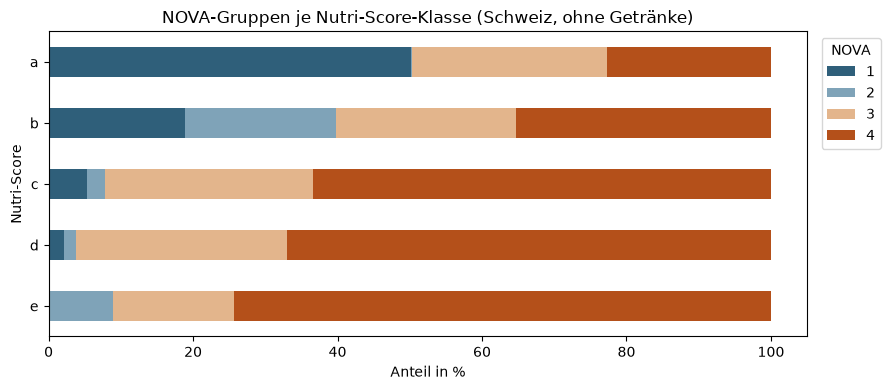

In [10]:
# Gestapeltes Balkendiagramm für die Präsentation (wird als PNG gespeichert)
import matplotlib.pyplot as plt
pct = ct.div(ct.sum(axis=1), axis=0) * 100
ax = pct.plot(kind="barh", stacked=True, figsize=(9, 4),
              color=["#2F5F7A", "#7FA3B8", "#E3B58C", "#B4501A"])   # Blau = wenig, Orange = stark verarbeitet
ax.set_xlabel("Anteil in %"); ax.set_ylabel("Nutri-Score"); ax.invert_yaxis()   # A oben
ax.legend(title="NOVA", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("NOVA-Gruppen je Nutri-Score-Klasse (Schweiz, ohne Getränke)")
plt.tight_layout(); plt.savefig(DATA_DIR / "nova_je_nutriscore.png", dpi=200); plt.show()

## 6 · Storage: Gold-Stufe

Kleine, fertig gefilterte Tabellen – je eine pro Hypothese. Sie sind die Schnittstelle zu *Serving* in Teil 2.
Alle Gold-Tabellen beziehen sich auf Lebensmittel **ohne Getränke** (eigener Nutri-Score-Algorithmus).

In [11]:
con.execute('''
-- H1: Anzahl A/B-Produkte und davon hochverarbeitete (NOVA 4)
CREATE OR REPLACE TABLE gold_h1_ab_nova AS
SELECT count(*) AS n_ab, sum((nova_group = 4)::INT) AS n_ab_nova4
FROM silver_products WHERE NOT ist_getraenk AND nutriscore_grade IN ('a','b');

-- H2: Häufigkeiten für die Kreuztabelle Nutri-Score × NOVA
CREATE OR REPLACE TABLE gold_h2_crosstab AS
SELECT nutriscore_grade, nova_group, count(*) AS n
FROM silver_products WHERE NOT ist_getraenk GROUP BY ALL;

-- H3: Frühstückscerealien mit A/B und Markierung "hoher Zuckergehalt"
-- Quelle Grenzwert 22,5 g/100 g: Department of Health & Food Standards Agency (2016),
-- Guide to creating a front of pack (FoP) nutrition label
CREATE OR REPLACE TABLE gold_h3_cereals AS
SELECT code, product_name, nutriscore_grade, sugars, sugars > 22.5 AS zucker_hoch
FROM silver_products
WHERE list_contains(categories_tags, 'en:breakfast-cereals')
  AND nutriscore_grade IN ('a','b') AND sugars IS NOT NULL;

-- H4: Anzahl Zusatzstoffe und Nutri-Score-Punkte pro Produkt
CREATE OR REPLACE TABLE gold_h4_additives AS
SELECT code, additives_n, nutriscore_score
FROM silver_products
WHERE NOT ist_getraenk AND additives_n IS NOT NULL AND nutriscore_score IS NOT NULL;
''')
con.sql("SELECT table_name FROM information_schema.tables WHERE table_name LIKE 'gold_%'").df()

,table_name
0,gold_h1_ab_nova
1,gold_h2_crosstab
2,gold_h3_cereals
3,gold_h4_additives


## 7 · Hypothesentests (α = 0,05)

| | Hypothese | Test | Entscheid |
|---|---|---|---|
| H1 | Mehr als 20 % der A/B-Produkte sind NOVA 4 | einseitiger Binomialtest, H0: p ≤ 0,20 | bestätigt, wenn p < α |
| H2 | Nutri-Score und NOVA hängen nur schwach zusammen | χ²-Unabhängigkeitstest + Cramér's V | bestätigt, wenn V < 0,3 |
| H3 | Mind. 10 % der A/B-Cerealien haben > 22,5 g Zucker/100 g | einseitiger Binomialtest, H0: p ≤ 0,10 | bestätigt, wenn p < α |
| H4 | Zusatzstoffe und Nutri-Score-Punkte korrelieren höchstens schwach | Spearman-Rangkorrelation | bestätigt, wenn \|ρ\| < 0,2 |

**Warum bei H2 und H4 die Effektstärke entscheidet:** Bei über 20'000 Produkten wird fast jeder noch so kleine
Zusammenhang signifikant. Der p-Wert sagt nur, *ob* ein Zusammenhang besteht; V bzw. ρ sagen, *wie stark* er ist.
Die Hypothesen sind Aussagen über die Stärke.

In [12]:
results = {}   # sammelt pro Hypothese: Kennzahl, Stichprobengrösse, p-Wert, Entscheid

# --- H1: Anteil NOVA 4 unter A/B grösser als 20 %? --------------------------
# Quelle: SciPy (2026). scipy.stats.binomtest. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html
n_ab, k_ab = con.sql("SELECT n_ab, n_ab_nova4 FROM gold_h1_ab_nova").fetchone()
t1 = stats.binomtest(int(k_ab), int(n_ab), p=0.20, alternative="greater")   # einseitig nach oben
results["H1"] = dict(kennzahl=f"{100*k_ab/n_ab:.1f} % NOVA 4 unter A/B", n=n_ab, p=t1.pvalue,
                     bestaetigt=t1.pvalue < ALPHA)

# --- H2: Stärke des Zusammenhangs Nutri-Score × NOVA ------------------------
# Quelle: SciPy (2026). scipy.stats.chi2_contingency.
# Cramér's V = sqrt(χ² / (n · (min(Zeilen, Spalten) − 1))), Quelle: Cramér, H. (1946). Mathematical Methods of Statistics.
tab = con.sql("SELECT * FROM gold_h2_crosstab").df().pivot(
    index="nutriscore_grade", columns="nova_group", values="n").fillna(0)
chi2, p2, dof, _ = stats.chi2_contingency(tab)
n2 = tab.to_numpy().sum()
cramers_v = (chi2 / (n2 * (min(tab.shape) - 1))) ** 0.5
results["H2"] = dict(kennzahl=f"Cramér's V = {cramers_v:.3f} (χ² = {chi2:.1f}, df = {dof})", n=int(n2), p=p2,
                     bestaetigt=cramers_v < 0.3)

# --- H3: Anteil zuckerreicher Cerealien unter A/B mindestens 10 %? ----------
n_c, k_c = con.sql("SELECT count(*), sum(zucker_hoch::INT) FROM gold_h3_cereals").fetchone()
if n_c:
    t3 = stats.binomtest(int(k_c), int(n_c), p=0.10, alternative="greater")
    results["H3"] = dict(kennzahl=f"{100*k_c/n_c:.1f} % mit > 22,5 g Zucker", n=n_c, p=t3.pvalue,
                         bestaetigt=t3.pvalue < ALPHA)
else:   # Schutz, falls die Kategorie im Datenstand fehlt
    results["H3"] = dict(kennzahl="keine Cerealien mit A/B gefunden", n=0, p=float("nan"), bestaetigt=None)

# --- H4: Korrelation Zusatzstoffe × Nutri-Score-Punkte -----------------------
# Spearman statt Pearson: additives_n ist eine Zählvariable, nicht normalverteilt.
# Quelle: SciPy (2026). scipy.stats.spearmanr.
h4 = con.sql("SELECT additives_n, nutriscore_score FROM gold_h4_additives").df()
rho, p4 = stats.spearmanr(h4["additives_n"], h4["nutriscore_score"])
results["H4"] = dict(kennzahl=f"rho = {rho:.3f}", n=len(h4), p=p4, bestaetigt=abs(rho) < 0.2)

# Ergebnistabelle: sehr kleine p-Werte als "< 0.001" anzeigen (statt 0.00e+00)
res = pd.DataFrame(results).T
res["p"] = res["p"].map(lambda v: "< 0.001" if pd.notna(v) and v < 0.001 else (f"{v:.3f}" if pd.notna(v) else "–"))
res["bestaetigt"] = res["bestaetigt"].map({True: "bestätigt", False: "verworfen", None: "nicht testbar"})
res

,kennzahl,n,p,bestaetigt
H1,27.7 % NOVA 4 unter A/B,4936,< 0.001,bestätigt
H2,"Cramér's V = 0.363 (χ² = 8064.8, df = 12)",20454,< 0.001,verworfen
H3,"1.1 % mit > 22,5 g Zucker",281,1.000,verworfen
H4,rho = 0.358,19870,< 0.001,verworfen


### Ergebnisse (Snapshot 06.10.2026)

| | Kennzahl | n | Entscheid | Deutung |
|---|---|---|---|---|
| H1 | 27,7 % NOVA 4 unter A/B, p < 0,001 | 4'936 | bestätigt | Ein gutes Label heisst oft nicht „wenig verarbeitet“ |
| H2 | Cramér's V = 0,363 | 20'454 | verworfen | Mittlerer statt schwacher Zusammenhang |
| H3 | 1,1 % mit > 22,5 g Zucker, p = 1,00 | 281 | verworfen | Zuckerreiche A/B-Cerealien sind selten |
| H4 | ρ = 0,358 | 19'870 | verworfen | Mehr Zusatzstoffe gehen mit schlechterem Score einher |

**Einschränkung:** Bei 82'186 von 105'693 Produkten fehlt der Nutri-Score oder die NOVA-Gruppe. Da nicht zufällig ist,
welche Produkte vollständig erfasst sind, ist eine Verzerrung möglich. Das wird in Teil 2 geprüft.

## 8 · Zusammenfassung und Datenstichprobe

Die erste Zelle druckt alle Werte für die Präsentation. Die zweite speichert eine kleine CSV-Stichprobe,
damit die Daten auf GitHub direkt angesehen werden können (die vollständigen Rohdaten sind zu gross für GitHub).

In [13]:
print(f"Snapshot-Datum: {SNAPSHOT_DATE}")
print(f"Bereinigung: vorher {n_bronze:,}, nachher {n_silver:,} (ohne Getränke {n_food:,})")
print(log.to_string())
print()
for h, r in results.items():
    p = ("< 0.001" if r['p'] < 0.001 else f"{r['p']:.3f}") if pd.notna(r['p']) else "–"
    status = {True: "bestätigt", False: "verworfen", None: "nicht testbar"}[r["bestaetigt"]]
    print(f"{h}: {r['kennzahl']} | n = {r['n']:,} | p = {p} -> {status}")

Snapshot-Datum: 2026-10-06
Bereinigung: vorher 105,693, nachher 22,949 (ohne Getränke 20,454)
                     betroffene_zeilen
Duplikate                            1
Unmögliche Werte                   267
Summe > 100 g                      218
Energie unplausibel               3933
Zielwerte fehlen                 82186
Getränke (separat)                8225

H1: 27.7 % NOVA 4 unter A/B | n = 4,936 | p = < 0.001 -> bestätigt
H2: Cramér's V = 0.363 (χ² = 8064.8, df = 12) | n = 20,454 | p = < 0.001 -> verworfen
H3: 1.1 % mit > 22,5 g Zucker | n = 281 | p = 1.000 -> verworfen
H4: rho = 0.358 | n = 19,870 | p = < 0.001 -> verworfen


In [14]:
# Zufällige, reproduzierbare Stichprobe von 1'000 bereinigten Produkten (fester Seed)
# Listen-Spalten werden für CSV als Text mit "|" als Trennzeichen gespeichert.
sample_file = SAMPLE_DIR / f"off_ch_silver_sample_1000_{SNAPSHOT_DATE}.csv"
con.execute(f'''
COPY (
    SELECT * REPLACE (array_to_string(categories_tags, '|') AS categories_tags)
    FROM silver_products
    USING SAMPLE reservoir(1000 ROWS) REPEATABLE (42)
) TO '{sample_file}' (HEADER, DELIMITER ',');
''')
print("Stichprobe gespeichert:", sample_file)

Stichprobe gespeichert: data\sample\off_ch_silver_sample_1000_2026-10-06.csv


In [15]:
# Datenbankverbindung sauber schliessen (sonst bleibt die DuckDB-Datei gesperrt)
con.close()

## Quellenverzeichnis

- Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton: Princeton University Press.
- Department of Health & Food Standards Agency (2016). *Guide to creating a front of pack (FoP) nutrition label for pre-packed products sold through retail outlets*. London.
- DuckDB Foundation (2026). *DuckDB Documentation: List Functions; Samples*. https://duckdb.org/docs
- Merz, B. et al. (2024). Nutri-Score 2023 update. *Nature Food, 5*(2), 102–110.
- Monteiro, C. A. et al. (2019). Ultra-processed foods: what they are and how to identify them. *Public Health Nutrition, 22*(5), 936–941.
- Open Food Facts (2026). *Data, API and SDKs*. https://world.openfoodfacts.org/data (ODbL 1.0)
- Reis, J. & Housley, M. (2022). *Fundamentals of Data Engineering*. Sebastopol: O'Reilly Media.
- SciPy (2026). *scipy.stats: binomtest, chi2_contingency, spearmanr*. https://docs.scipy.org/doc/scipy/reference/stats.html
- Verordnung (EU) Nr. 1169/2011 betreffend die Information der Verbraucher über Lebensmittel, Anhang XIV (Umrechnungsfaktoren).